# 🧠 Transfer Learning — Feature Extraction: Clasificación Binaria
## 🛰️ Detección de barcos en imágenes satelitales

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps
**Integrantes:** _______________________________________________

---

### 🎯 Objetivos de este notebook
1. **Aplicar** Feature Extraction con un backbone pre-entrenado en ImageNet (MobileNetV2) a un problema real
2. **Resolver** una clasificación **binaria desbalanceada** (barco / no barco)
3. **Evaluar** con métricas adecuadas al desbalance: precision, recall, F1, ROC-AUC
4. **Convertir** el clasificador en un detector que escanea una escena satelital completa

### 📚 Estructura
| Sección | Contenido |
|---------|-----------|
| 1.1 | Descarga y EDA del dataset |
| 1.2 | Preprocesamiento + augmentation satelital |
| 1.3 | Modelo: MobileNetV2 congelado + Dense(1, sigmoid) |
| 1.4 | Entrenamiento con `class_weight` |
| 1.5 | Evaluación en test: reporte, matriz de confusión, curva ROC |
| 1.6 | Predicciones visuales y análisis de errores |
| 1.7 | Aplicación real: escaneo de una escena completa |

### 🌎 Problemática
Revisar a mano miles de km² de imágenes satelitales para encontrar embarcaciones (pesca ilegal, control de puertos, rescate) es inviable. Un clasificador que detecte barcos permite **escanear escenas completas automáticamente**.

## ⚙️ Configuración del Entorno

Verificamos GPU disponible e instalamos dependencias.

In [ ]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                          '--format=csv,noheader'], capture_output=True, text=True)
print("🖥️ GPU detectada:", gpu_info.stdout.strip() or "⚠️ No hay GPU — activa en Runtime > Change runtime type > T4 GPU")

🖥️ GPU detectada: NVIDIA A100-SXM4-40GB, 40960 MiB


In [ ]:
!pip install -q kagglehub

import os, glob, re, time
import kagglehub
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)
import warnings
warnings.filterwarnings('ignore')

# Configuración global
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU disponible: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow 2.21.0
✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


> 🔑 **Sobre Kaggle:** `kagglehub.dataset_download(...)` descarga datasets públicos. Si Colab te pide credenciales, ejecuta `kagglehub.login()` y pega tu usuario y API key (Kaggle → Settings → API → *Create New Token*).
>
> Usamos `dataset_download` (descarga la carpeta completa) en lugar de `load_dataset(KaggleDatasetAdapter.PANDAS, ...)`, porque ese adaptador es para archivos **tabulares** (CSV, JSON) y aquí trabajamos con **imágenes**.

---
# 📖 Fundamentos de Transfer Learning

## ¿Qué es Transfer Learning?

> **Transferir conocimiento** de una tarea donde hay abundancia de datos (ej. ImageNet: 14M imágenes, 1000 clases) a una tarea donde tenemos pocos datos (nuestro problema específico).

### ¿Por qué funciona en CNNs?
Las capas de una CNN entrenada en ImageNet aprenden features progresivamente más abstractos:

```
Capa 1-3:  Bordes, gradientes, colores      → UNIVERSALES (útiles para cualquier imagen)
Capa 4-7:  Texturas, patrones repetitivos   → SEMI-UNIVERSALES
Capa 8-12: Partes de objetos (ojos, ruedas) → SEMI-ESPECÍFICOS
Capa 13+:  Objetos completos (gato, auto)   → ESPECÍFICOS de ImageNet
```

Nuestros dos problemas **no se parecen a ImageNet** (vistas satelitales y granos de arroz sobre fondo negro), pero los bordes, texturas y formas que aprendió la red siguen siendo útiles. Eso es justamente lo que vamos a comprobar.

### Feature Extraction (lo que hacemos hoy)
1. Tomamos un modelo pre-entrenado en ImageNet
2. **Congelamos** todo su backbone (las capas que extraen features)
3. Removemos su clasificador original (1000 clases)
4. Agregamos un **nuevo clasificador** para nuestras clases
5. Entrenamos **solo** el clasificador nuevo

---
# 🟢 Detección de barcos en imágenes satelitales con MobileNetV2

**Objetivo:** Clasificación **binaria** (barco / no barco) sobre recortes de imágenes satelitales usando MobileNetV2 congelado. Luego usamos el modelo para **escanear una escena satelital completa** y ubicar los barcos.

**Dataset:** [Ships in Satellite Imagery](https://www.kaggle.com/datasets/rhammell/ships-in-satellite-imagery) — 4,000 recortes RGB de **80×80 px** extraídos de imágenes de Planet sobre las bahías de San Francisco y San Pedro (California).
- **1,000** recortes con barco (`label = 1`) y **3,000** sin barco (`label = 0`): mar, tierra, muelles, barcos cortados a la mitad, etc.
- Nombre de cada archivo: `{label}__{scene_id}__{longitud}_{latitud}.png`
- Incluye además **escenas completas** (`scenes/`) para probar el modelo en un caso real.

**Retos nuevos frente a Cats vs Dogs:**
1. ⚖️ **Desbalance 1:3** → usamos `class_weight` y métricas más allá del accuracy (precision, recall, F1, AUC)
2. 🔍 **Imágenes pequeñas (80×80)** → las ampliamos a 224×224, que es lo que espera MobileNetV2
3. 🧭 **Vista cenital** → un barco es un barco en cualquier orientación, así que usamos flips y rotaciones de 90°

### 1.1. Descargar y explorar el dataset

In [ ]:
# Descargar dataset (la primera vez tarda; después queda en caché)
path_ships = kagglehub.dataset_download("rhammell/ships-in-satellite-imagery")
print("📁 Carpeta del dataset:", path_ships)

# Ver estructura de carpetas
for root, dirs, files in os.walk(path_ships):
    nivel = root.replace(path_ships, '').count(os.sep)
    if nivel <= 3:
        print('   ' * nivel + f"📂 {os.path.basename(root) or root}  ({len(files)} archivos)")

100%|██████████| 185M/185M [00:01<00:00, 138MB/s]

Extracting files...


📁 Carpeta del dataset: /root/.cache/kagglehub/datasets/rhammell/ships-in-satellite-imagery/versions/9
📂 9  (1 archivos)
   📂 scenes  (0 archivos)
      📂 scenes  (8 archivos)
   📂 shipsnet  (0 archivos)
      📂 shipsnet  (4000 archivos)


In [ ]:
# Recolectar todos los PNG (búsqueda recursiva: no dependemos de la estructura exacta)
all_png = glob.glob(os.path.join(path_ships, '**', '*.png'), recursive=True)

# Recortes etiquetados: el nombre empieza con "0__" o "1__"
chips = {}
for p in all_png:
    nombre = os.path.basename(p)
    if re.match(r'^[01]__', nombre):
        chips.setdefault(nombre, p)          # evita duplicados si la carpeta viene repetida
chip_paths = np.array(sorted(chips.values()))
chip_labels = np.array([int(os.path.basename(p)[0]) for p in chip_paths])

# Escenas completas (para la sección 1.7)
# (son los PNG que están dentro de la carpeta "scenes" y no son recortes etiquetados)
scene_paths = sorted({os.path.basename(p): p for p in all_png
                      if os.path.basename(os.path.dirname(p)).lower() == 'scenes'
                      and not re.match(r'^[01]__', os.path.basename(p))}.values())
print("🗺️ Escenas:", [os.path.basename(p) for p in scene_paths])

NUM_CLASSES_1 = 2
CLASS_NAMES_1 = ['no_barco', 'barco']

print(f"🛰️ Recortes etiquetados: {len(chip_paths):,}")
print(f"   🚢 barco:    {(chip_labels == 1).sum():,}")
print(f"   🌊 no_barco: {(chip_labels == 0).sum():,}")
print(f"🗺️ Escenas completas: {len(scene_paths)}")

🗺️ Escenas: ['lb_1.png', 'lb_2.png', 'lb_3.png', 'lb_4.png', 'sfbay_1.png', 'sfbay_2.png', 'sfbay_3.png', 'sfbay_4.png']
🛰️ Recortes etiquetados: 4,000
   🚢 barco:    1,000
   🌊 no_barco: 3,000
🗺️ Escenas completas: 8


In [ ]:
# División estratificada 70% train / 15% val / 15% test (mantiene la proporción 1:3)
X_tmp, X_test_1, y_tmp, y_test_1 = train_test_split(
    chip_paths, chip_labels, test_size=0.15, stratify=chip_labels, random_state=SEED)
X_train_1, X_val_1, y_train_1, y_val_1 = train_test_split(
    X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)

df_split_1 = pd.DataFrame({
    'Conjunto': ['Train', 'Val', 'Test'],
    'Total': [len(y_train_1), len(y_val_1), len(y_test_1)],
    'barco': [(y_train_1 == 1).sum(), (y_val_1 == 1).sum(), (y_test_1 == 1).sum()],
    'no_barco': [(y_train_1 == 0).sum(), (y_val_1 == 0).sum(), (y_test_1 == 0).sum()],
})
df_split_1['% barco'] = (df_split_1['barco'] / df_split_1['Total'] * 100).round(1)
print(df_split_1.to_string(index=False))

Conjunto  Total  barco  no_barco  % barco
   Train   2800    700      2100     25.0
     Val    600    150       450     25.0
    Test    600    150       450     25.0


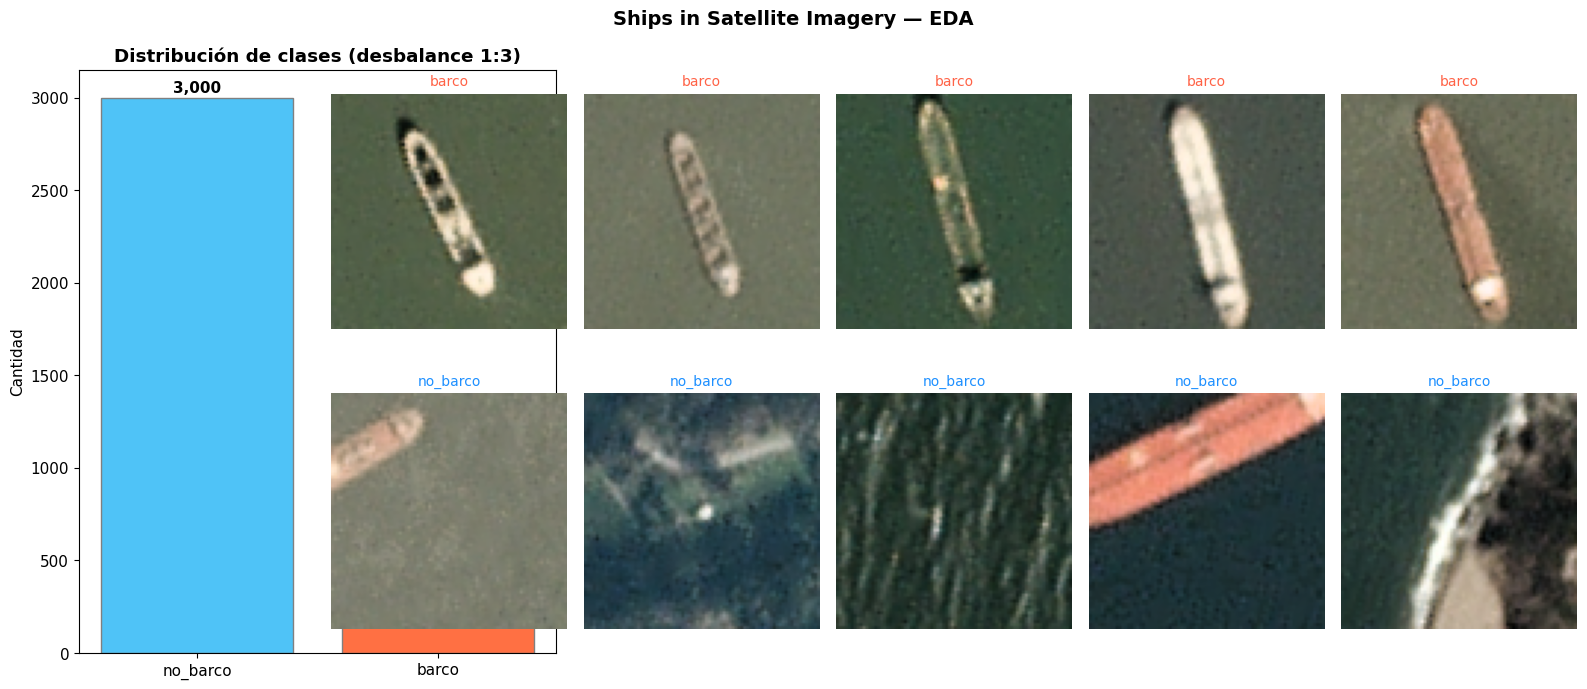

📐 Tamaño de cada recorte: (80, 80, 3)


In [ ]:
# EDA: distribución de clases y muestras
fig = plt.figure(figsize=(16, 7))

# Distribución (gráfico de barras)
ax0 = fig.add_subplot(1, 3, 1)
counts = [(chip_labels == 0).sum(), (chip_labels == 1).sum()]
bars = ax0.bar(CLASS_NAMES_1, counts, color=['#4FC3F7', '#FF7043'], edgecolor='gray')
for b, c in zip(bars, counts):
    ax0.text(b.get_x() + b.get_width() / 2, b.get_height() + 30, f'{c:,}',
             ha='center', fontweight='bold')
ax0.set_title('Distribución de clases (desbalance 1:3)', fontweight='bold')
ax0.set_ylabel('Cantidad')

# Muestras: 5 barcos y 5 no barcos
rng = np.random.default_rng(SEED)
idx_ship = rng.choice(np.where(chip_labels == 1)[0], 5, replace=False)
idx_noship = rng.choice(np.where(chip_labels == 0)[0], 5, replace=False)
for k, idx in enumerate(list(idx_ship) + list(idx_noship)):
    ax = fig.add_subplot(2, 6, (k // 5) * 6 + (k % 5) + 2)
    img = tf.io.decode_png(tf.io.read_file(chip_paths[idx]), channels=3).numpy()
    ax.imshow(img)
    ax.set_title(CLASS_NAMES_1[chip_labels[idx]], fontsize=10,
                 color='tomato' if chip_labels[idx] == 1 else 'dodgerblue')
    ax.axis('off')

plt.suptitle('Ships in Satellite Imagery — EDA', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"📐 Tamaño de cada recorte: {img.shape}")

### 1.2. Preprocesamiento

1. **Lectura:** decodificamos los PNG con `tf.data` y los guardamos en caché (4,000 imágenes de 80×80 ocupan muy poca RAM).
2. **Augmentation (solo train):** flips horizontal/vertical y rotaciones de 90°. En una vista satelital no existe "arriba" ni "abajo".
3. **Resize 80×80 → 224×224** y `mobilenet_v2.preprocess_input` (píxeles en [-1, 1]).
4. **Etiqueta escalar (0/1):** como es binaria, la salida será **1 neurona sigmoide** con `binary_crossentropy`.

In [ ]:
IMG_SIZE_1 = (224, 224)

def load_png(path, label):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    return img, label

def make_raw_ds(paths, labels, loader):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), np.array(labels, dtype=np.int32)))
    return ds.map(loader, num_parallel_calls=AUTOTUNE)

# Datasets "crudos" (uint8, 80×80) en caché
train_raw_1 = make_raw_ds(X_train_1, y_train_1, load_png).cache()
val_raw_1   = make_raw_ds(X_val_1,   y_val_1,   load_png).cache()
test_raw_1  = make_raw_ds(X_test_1,  y_test_1,  load_png).cache()

def augment_satelite(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    k = tf.random.uniform([], 0, 4, dtype=tf.int32)     # 0°, 90°, 180° o 270°
    image = tf.image.rot90(image, k)
    return image, label

def preprocess_example1(image, label):
    image = tf.image.resize(tf.cast(image, tf.float32), IMG_SIZE_1)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)   # → [-1, 1]
    return image, tf.cast(label, tf.float32)

train_ds_1 = (train_raw_1
    .shuffle(len(X_train_1), seed=SEED)
    .map(augment_satelite, num_parallel_calls=AUTOTUNE)
    .map(preprocess_example1, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

val_ds_1 = (val_raw_1
    .map(preprocess_example1, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

test_ds_1 = (test_raw_1
    .map(preprocess_example1, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

# Verificar un batch
for imgs, labels in train_ds_1.take(1):
    print(f"✅ Batch shape: {imgs.shape}")
    print(f"✅ Labels shape: {labels.shape}  →  ejemplo: {labels[:8].numpy()}")
    print(f"✅ Rango de píxeles: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

✅ Batch shape: (32, 224, 224, 3)
✅ Labels shape: (32,)  →  ejemplo: [0. 0. 0. 0. 0. 0. 0. 0.]
✅ Rango de píxeles: [-0.96, 1.00]


### 1.3. Construir modelo con Feature Extraction

**Pasos clave:**
1. Cargar MobileNetV2 **sin** el clasificador (`include_top=False`)
2. **Congelar** todas sus capas (`trainable = False`)
3. Agregar un clasificador binario: `GlobalAveragePooling2D → Dropout → Dense(1, sigmoid)`

> La salida sigmoide da directamente **P(barco)**. Con 2 clases es equivalente a usar softmax de 2 neuronas, pero con la mitad de parámetros en la última capa.

In [ ]:
# 1. Cargar backbone pre-entrenado (SIN clasificador de ImageNet)
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_1, 3)
)

# 2. CONGELAR todo el backbone
base_model_1.trainable = False

print(f"📐 Backbone: MobileNetV2")
print(f"📐 Capas totales: {len(base_model_1.layers)}")
print(f"📐 Parámetros totales: {base_model_1.count_params():,}")
print(f"📐 Parámetros entrenables: 0  (todo congelado)")
print(f"📐 Output shape: {base_model_1.output_shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 Backbone: MobileNetV2
📐 Capas totales: 154
📐 Parámetros totales: 2,257,984
📐 Parámetros entrenables: 0  (todo congelado)
📐 Output shape: (None, 7, 7, 1280)


In [ ]:
# 3. Construir modelo completo: backbone congelado + nuevo clasificador binario
inputs_1 = layers.Input(shape=(*IMG_SIZE_1, 3))
x = base_model_1(inputs_1, training=False)        # BatchNorm en modo inferencia
x = layers.GlobalAveragePooling2D(name='gap')(x)  # 7×7×1280 → 1280
x = layers.Dropout(0.3)(x)
outputs_1 = layers.Dense(1, activation='sigmoid', name='p_barco')(x)

model_1 = models.Model(inputs_1, outputs_1, name='ships_mobilenetv2_FE')
model_1.summary()

total = model_1.count_params()
trainable = sum(tf.size(w).numpy() for w in model_1.trainable_weights)
print(f"\n🔢 Total: {total:,} parámetros")
print(f"🔓 Entrenables: {trainable:,} ({trainable/total*100:.3f}%)")
print(f"🔒 Congelados: {total - trainable:,} ({(total-trainable)/total*100:.2f}%)")

Model: "ships_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_barco (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔢 Total: 2,259,265 parámetros
🔓 Entrenables: 1,281 (0.057%)
🔒 Congelados: 2,257,984 (99.94%)


> 💡 **Observa:** solo se entrenan **1,281 parámetros** (1280 pesos + 1 bias). Los ~2.2M del backbone están congelados.

### 1.4. Entrenar con pesos de clase

Como hay 3 veces más "no barco" que "barco", un modelo que siempre diga "no barco" ya tendría **75% de accuracy** sin haber aprendido nada. Para evitarlo:
- **`class_weight`**: cada error en la clase minoritaria (barco) pesa más en la función de pérdida.
- **Métricas adicionales**: `precision`, `recall` y `AUC`, que sí reflejan si el modelo detecta los barcos.

In [ ]:
# Pesos de clase inversamente proporcionales a la frecuencia
n_neg, n_pos = np.bincount(y_train_1)
class_weight_1 = {0: (n_neg + n_pos) / (2 * n_neg),
                  1: (n_neg + n_pos) / (2 * n_pos)}
print(f"⚖️ class_weight: no_barco = {class_weight_1[0]:.3f} | barco = {class_weight_1[1]:.3f}")

model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=12,
    class_weight=class_weight_1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True)
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_1.history['val_accuracy']):.4f}")
print(f"🏆 Mejor val_auc:      {max(history_1.history['val_auc']):.4f}")

⚖️ class_weight: no_barco = 0.667 | barco = 2.000
Epoch 1/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 45s 302ms/step - accuracy: 0.8639 - auc: 0.9532 - loss: 0.2784 - precision: 0.6677 - recall: 0.9071 - val_accuracy: 0.9050 - val_auc: 0.9848 - val_loss: 0.1893 - val_precision: 0.7360 - val_recall: 0.9667
Epoch 2/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9232 - auc: 0.9841 - loss: 0.1669 - precision: 0.7810 - recall: 0.9629 - val_accuracy: 0.9117 - val_auc: 0.9896 - val_loss: 0.1737 - val_precision: 0.7437 - val_recall: 0.9867
Epoch 3/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9354 - auc: 0.9907 - loss: 0.1346 - precision: 0.8086 - recall: 0.9714 - val_accuracy: 0.9383 - val_auc: 0.9915 - val_loss: 0.1290 - val_precision: 0.8156 - val_recall: 0.9733
Epoch 4/12
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9357 - auc: 0.9895 - loss: 0.1354 - precision: 0.8088 - recall: 0.9729 - val_accuracy: 0.9467 - val_auc: 0.9927 - val_loss: 0.1236 - val_precision: 0.8315 - val

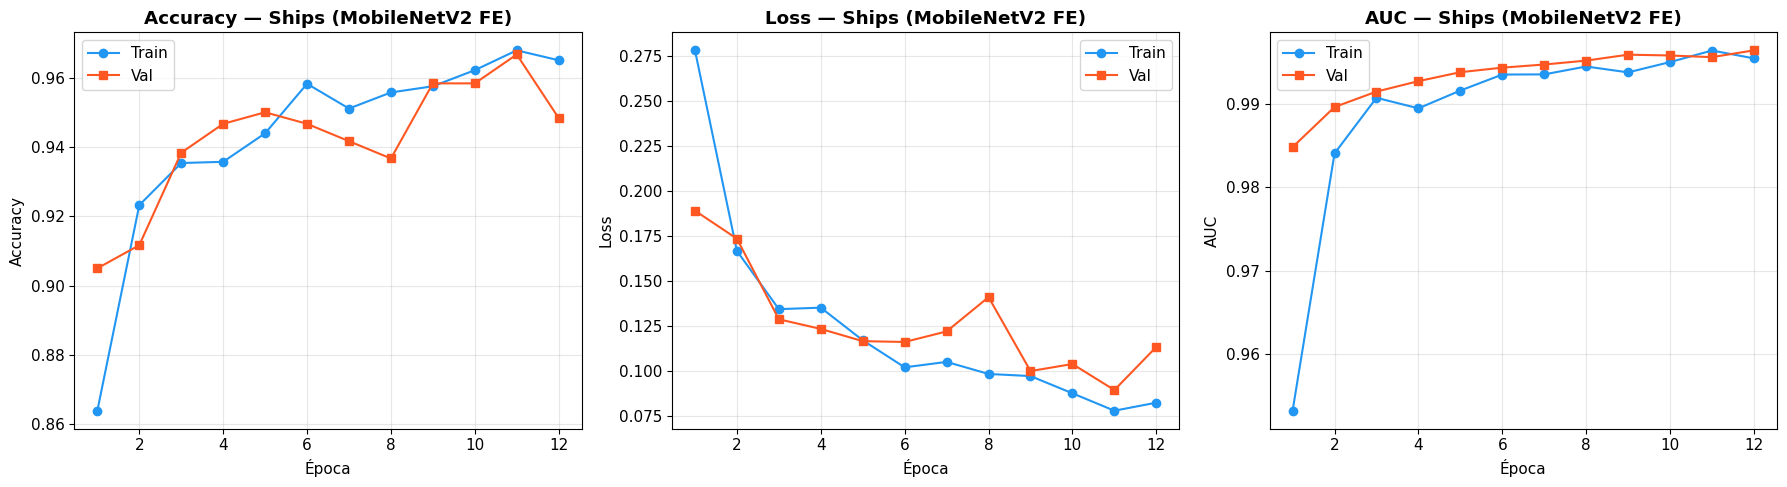

In [ ]:
# Curvas de aprendizaje
h1 = history_1.history
ep = range(1, len(h1['accuracy']) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metrica, titulo in [(axes[0], 'accuracy', 'Accuracy'),
                            (axes[1], 'loss', 'Loss'),
                            (axes[2], 'auc', 'AUC')]:
    ax.plot(ep, h1[metrica], 'o-', label='Train', color='#2196F3')
    ax.plot(ep, h1['val_' + metrica], 's-', label='Val', color='#FF5722')
    ax.set_title(f'{titulo} — Ships (MobileNetV2 FE)', fontweight='bold')
    ax.set_xlabel('Época'); ax.set_ylabel(titulo)
    ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5. Evaluación en el conjunto de TEST

Evaluamos en datos que el modelo **nunca vio** (ni para entrenar ni para elegir la mejor época).

In [ ]:
# Probabilidades P(barco) sobre test (el orden coincide con X_test_1 / y_test_1)
probs_test_1 = model_1.predict(test_ds_1, verbose=0).ravel()
UMBRAL_1 = 0.5
y_pred_1 = (probs_test_1 >= UMBRAL_1).astype(int)

print("📊 Classification Report — Ships (MobileNetV2 FE) — TEST")
print("=" * 65)
print(classification_report(y_test_1, y_pred_1, target_names=CLASS_NAMES_1, digits=4))
print(f"🎯 ROC-AUC (test): {roc_auc_score(y_test_1, probs_test_1):.4f}")

📊 Classification Report — Ships (MobileNetV2 FE) — TEST
              precision    recall  f1-score   support

    no_barco     0.9954    0.9533    0.9739       450
       barco     0.8757    0.9867    0.9279       150

    accuracy                         0.9617       600
   macro avg     0.9355    0.9700    0.9509       600
weighted avg     0.9655    0.9617    0.9624       600

🎯 ROC-AUC (test): 0.9957


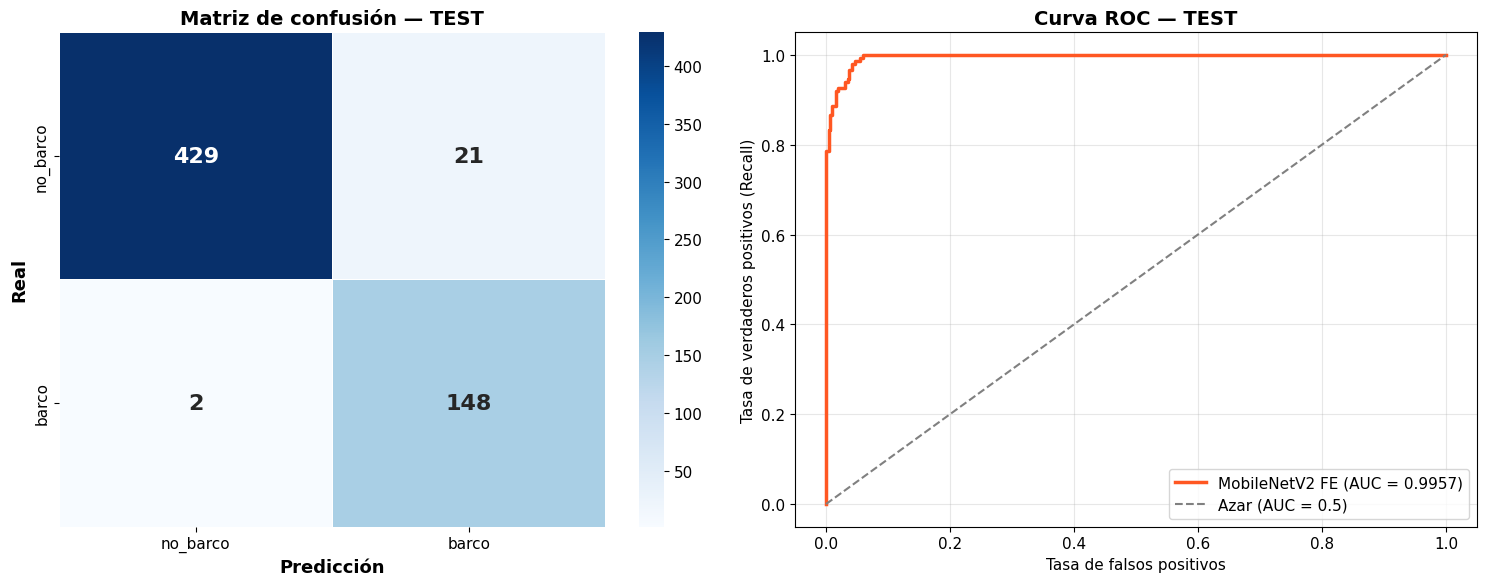

✅ Barcos detectados correctamente (TP): 148
❌ Barcos que se escaparon (FN):        2
⚠️ Falsas alarmas (FP):                 21


In [ ]:
# Matriz de confusión + Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

cm_1 = confusion_matrix(y_test_1, y_pred_1)
sns.heatmap(cm_1, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES_1, yticklabels=CLASS_NAMES_1, ax=axes[0],
            linewidths=0.5, linecolor='white', annot_kws={'size': 16, 'fontweight': 'bold'})
axes[0].set_xlabel('Predicción', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Real', fontsize=13, fontweight='bold')
axes[0].set_title('Matriz de confusión — TEST', fontsize=14, fontweight='bold')

fpr, tpr, _ = roc_curve(y_test_1, probs_test_1)
auc_1 = roc_auc_score(y_test_1, probs_test_1)
axes[1].plot(fpr, tpr, color='#FF5722', linewidth=2.5, label=f'MobileNetV2 FE (AUC = {auc_1:.4f})')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Azar (AUC = 0.5)')
axes[1].set_xlabel('Tasa de falsos positivos'); axes[1].set_ylabel('Tasa de verdaderos positivos (Recall)')
axes[1].set_title('Curva ROC — TEST', fontsize=14, fontweight='bold')
axes[1].legend(loc='lower right'); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_1.ravel()
print(f"✅ Barcos detectados correctamente (TP): {tp}")
print(f"❌ Barcos que se escaparon (FN):        {fn}")
print(f"⚠️ Falsas alarmas (FP):                 {fp}")

### 1.6. Predicciones visuales y análisis de errores

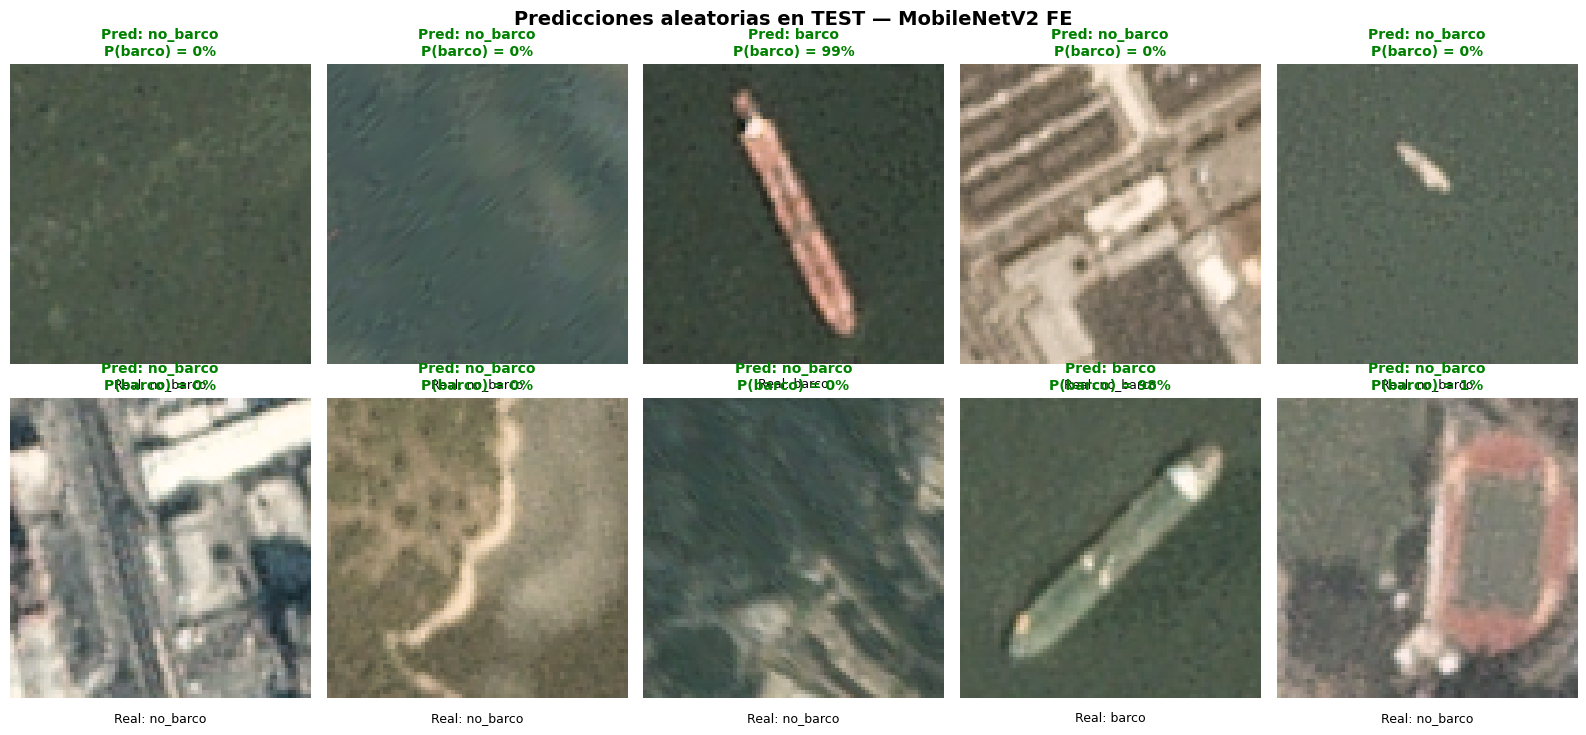

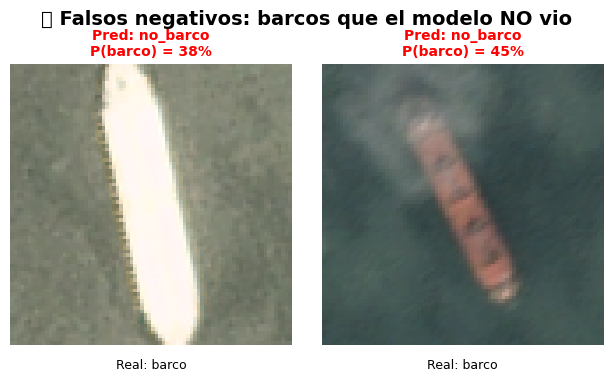

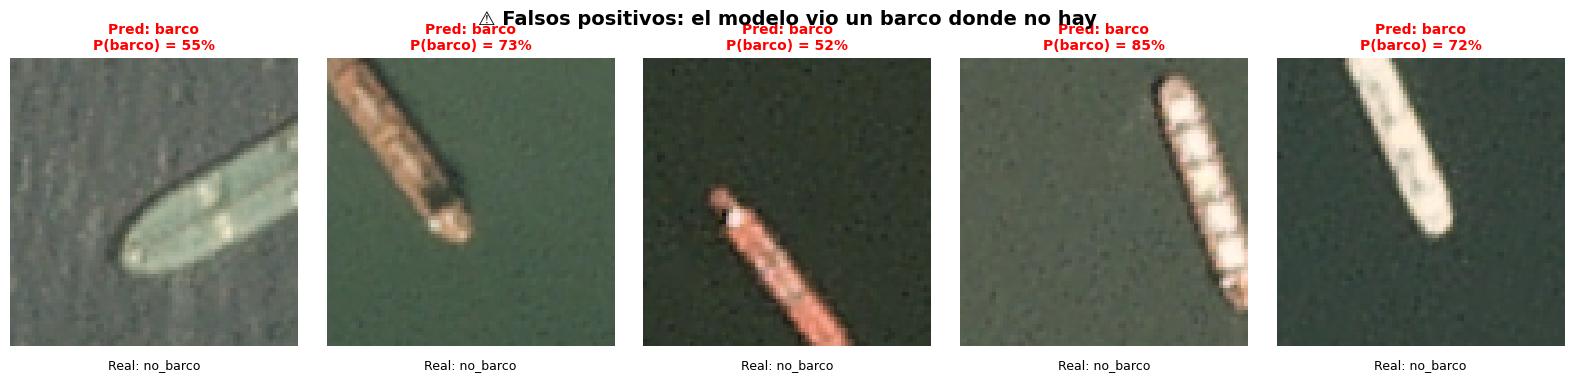

In [ ]:
def mostrar_chips(indices, titulo):
    n = len(indices)
    if n == 0:
        print(f"(sin imágenes para: {titulo})")
        return
    cols = min(n, 5); rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, i in zip(axes.ravel(), indices):
        img = tf.io.decode_png(tf.io.read_file(X_test_1[i]), channels=3).numpy()
        pred = CLASS_NAMES_1[y_pred_1[i]]; real = CLASS_NAMES_1[y_test_1[i]]
        ax.imshow(img)
        ax.set_title(f"Pred: {pred}\nP(barco) = {probs_test_1[i]:.0%}", fontsize=10,
                     color='green' if pred == real else 'red', fontweight='bold')
        ax.text(0.5, -0.08, f"Real: {real}", transform=ax.transAxes, ha='center', fontsize=9)
    plt.suptitle(titulo, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
mostrar_chips(rng.choice(len(X_test_1), 10, replace=False),
              'Predicciones aleatorias en TEST — MobileNetV2 FE')

idx_fn = np.where((y_test_1 == 1) & (y_pred_1 == 0))[0][:5]
idx_fp = np.where((y_test_1 == 0) & (y_pred_1 == 1))[0][:5]
mostrar_chips(idx_fn, '❌ Falsos negativos: barcos que el modelo NO vio')
mostrar_chips(idx_fp, '⚠️ Falsos positivos: el modelo vio un barco donde no hay')

> 📝 **Analiza los errores:** los falsos positivos suelen ser **barcos cortados a la mitad**, muelles o estructuras alargadas (en el dataset están etiquetados como "no barco"). Los falsos negativos suelen ser barcos muy pequeños o con poco contraste respecto al agua.

### 1.7. 🌍 Aplicación real: escanear una escena satelital completa

El modelo clasifica recortes de 80×80. Para usarlo en una imagen satelital grande, la recorremos con una **ventana deslizante** de 80×80, clasificamos cada ventana y nos quedamos con las de mayor probabilidad.

**Dos detalles importantes:**
1. **Paso pequeño (20 px):** en el dataset, un barco *cortado por el borde* está etiquetado como "no barco". Así que el modelo aprendió a reconocer barcos **centrados** en el recorte. Con un paso grande (40 px) casi ninguna ventana cae centrada sobre un barco y se pierden detecciones.
2. **Non-Maximum Suppression (NMS):** con un paso de 20 px, varias ventanas vecinas marcan el mismo barco. NMS deja solo la ventana de mayor probabilidad de cada grupo superpuesto.

> Así se convierte un **clasificador** en un **detector** sencillo, que es lo que necesitaría un sistema de vigilancia marítima.

🗺️ Escena: lb_1.png — 2001×1749 px
🔍 Ventanas a clasificar: 8,148
⏱️ Tiempo de escaneo: 20.6 s
📦 Ventanas sobre el umbral: 15 → después de NMS: 5 barcos detectados


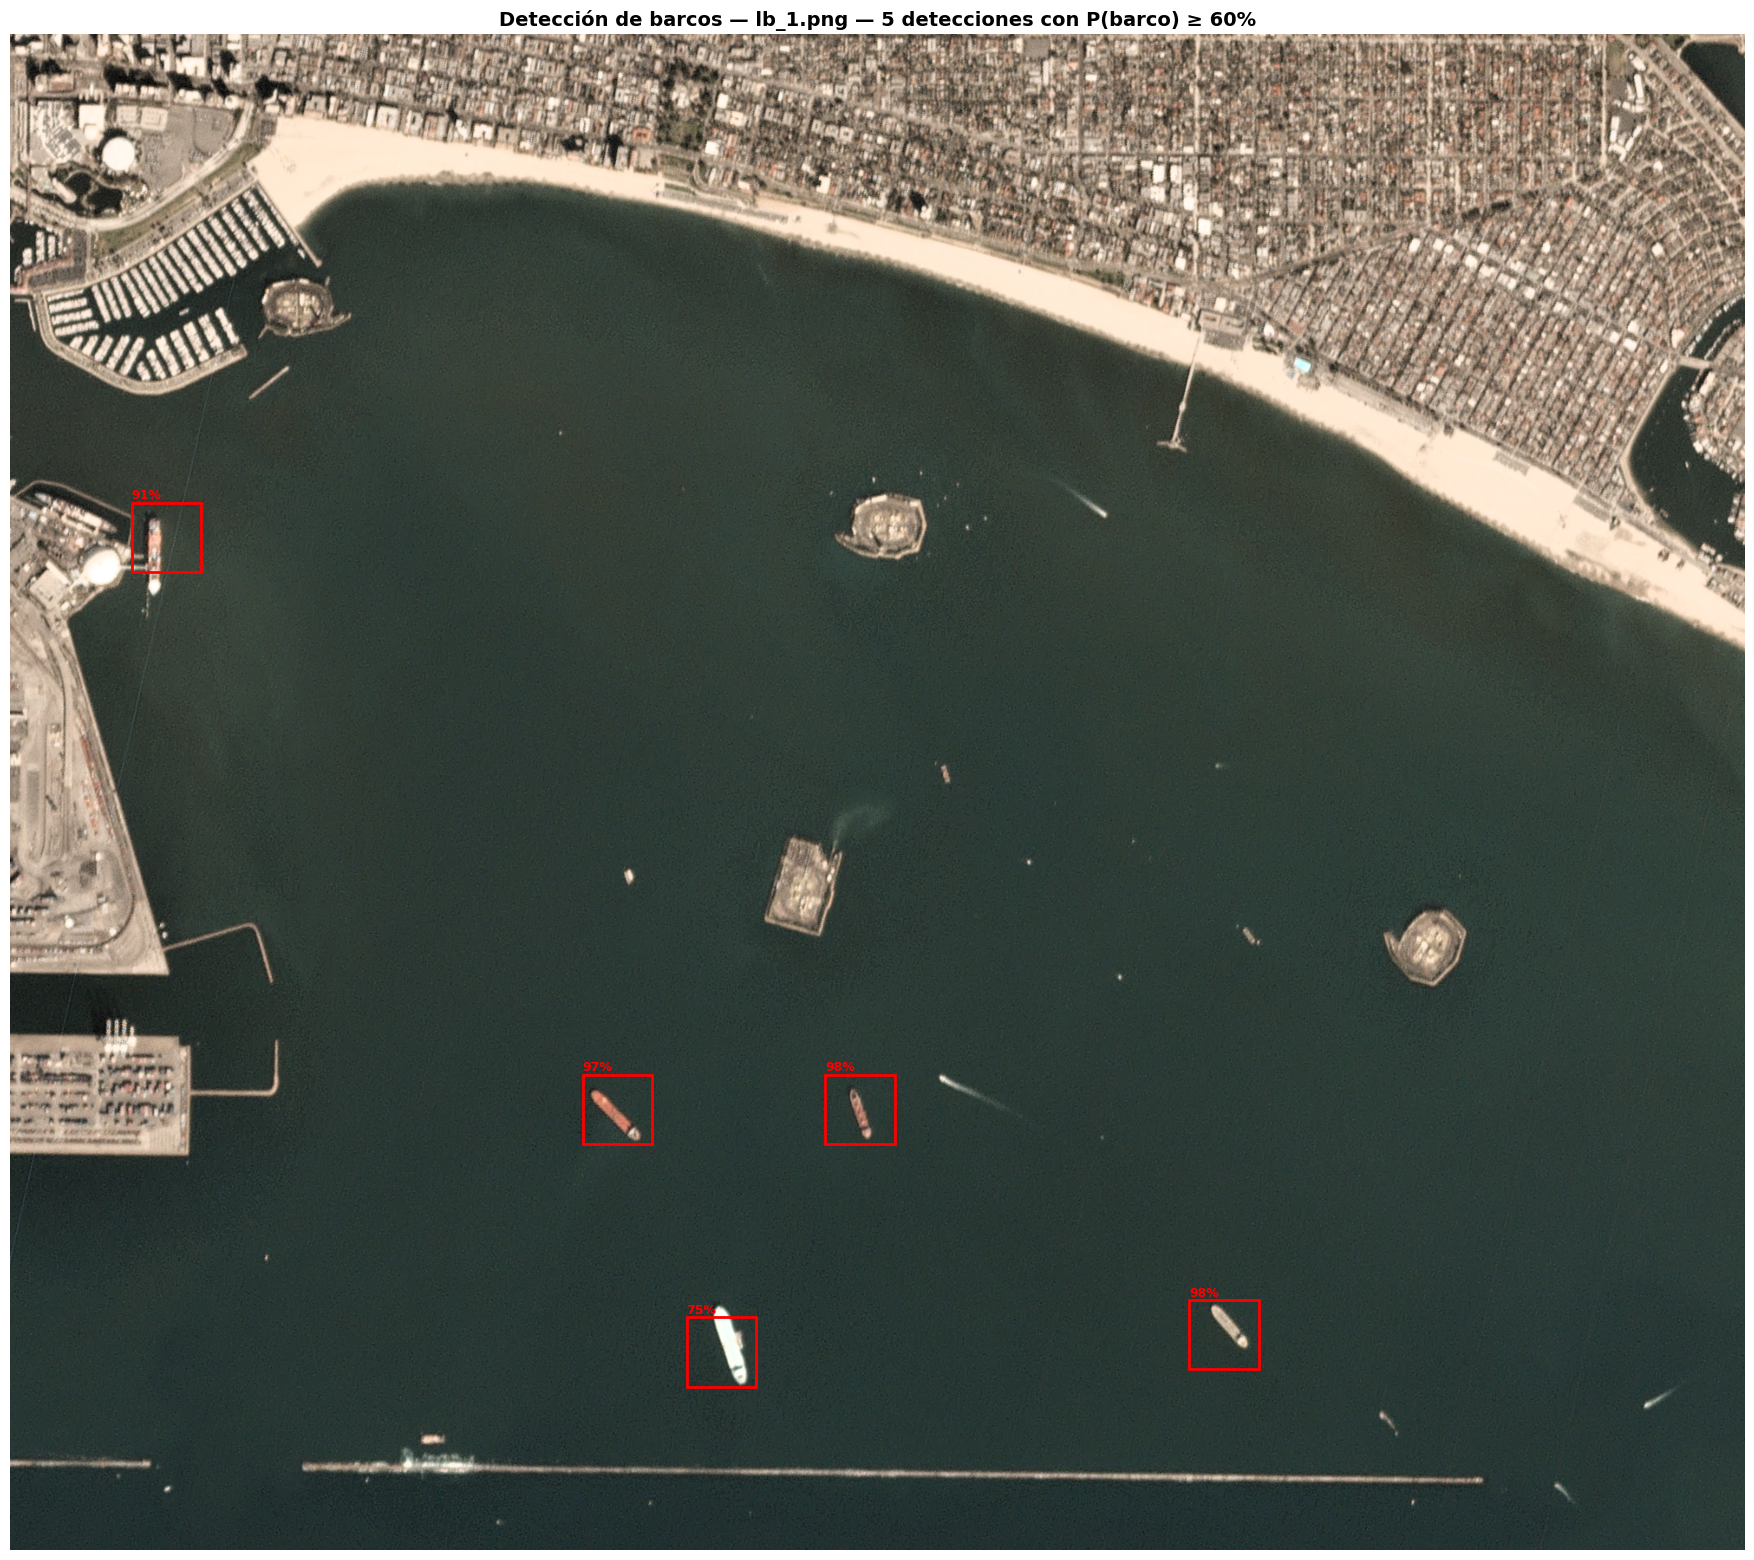

In [ ]:
SCENE_IDX = 0          # ⚙️ hay 8 escenas: 0-3 = lb_* (San Pedro), 4-7 = sfbay_* (San Francisco)
WIN, STRIDE = 80, 20   # ventana del tamaño de los recortes, paso pequeño
UMBRAL_ESCENA = 0.60   # ⚙️ súbelo (0.8-0.9) si salen muchas falsas alarmas
IOU_NMS = 0.20         # ventanas que se superponen más de esto se fusionan

if len(scene_paths) == 0:
    print("⚠️ No se encontraron escenas completas en el dataset.")
else:
    scene = tf.io.decode_png(tf.io.read_file(scene_paths[SCENE_IDX]), channels=3).numpy()
    H, W, _ = scene.shape
    print(f"🗺️ Escena: {os.path.basename(scene_paths[SCENE_IDX])} — {W}×{H} px")

    # 1. Generar ventanas
    coords, crops = [], []
    for yy in range(0, H - WIN + 1, STRIDE):
        for xx in range(0, W - WIN + 1, STRIDE):
            coords.append((xx, yy))
            crops.append(scene[yy:yy + WIN, xx:xx + WIN])
    crops = np.stack(crops)
    coords = np.array(coords)
    print(f"🔍 Ventanas a clasificar: {len(crops):,}")

    # 2. Clasificar en lotes
    t0 = time.time()
    probs_scene = []
    for i in range(0, len(crops), 256):
        lote = tf.image.resize(tf.cast(crops[i:i + 256], tf.float32), IMG_SIZE_1)
        lote = tf.keras.applications.mobilenet_v2.preprocess_input(lote)
        probs_scene.append(model_1.predict(lote, verbose=0).ravel())
    probs_scene = np.concatenate(probs_scene)
    print(f"⏱️ Tiempo de escaneo: {time.time() - t0:.1f} s")

    # 3. Non-Maximum Suppression: una caja por barco
    boxes = np.stack([coords[:, 1], coords[:, 0],
                      coords[:, 1] + WIN, coords[:, 0] + WIN], axis=1).astype(np.float32)
    keep = tf.image.non_max_suppression(
        boxes, probs_scene.astype(np.float32), max_output_size=300,
        iou_threshold=IOU_NMS, score_threshold=UMBRAL_ESCENA).numpy()
    n_antes = int((probs_scene >= UMBRAL_ESCENA).sum())
    print(f"📦 Ventanas sobre el umbral: {n_antes} → después de NMS: {len(keep)} barcos detectados")

    # 4. Dibujar detecciones
    fig, ax = plt.subplots(figsize=(18, 18 * H / W))
    ax.imshow(scene)
    for k in keep:
        xx, yy = coords[k]
        ax.add_patch(plt.Rectangle((xx, yy), WIN, WIN, fill=False,
                                   edgecolor='red', linewidth=2))
        ax.text(xx, yy - 4, f'{probs_scene[k]:.0%}', color='red',
                fontsize=9, fontweight='bold')
    ax.set_title(f'Detección de barcos — {os.path.basename(scene_paths[SCENE_IDX])} — '
                 f'{len(keep)} detecciones con P(barco) ≥ {UMBRAL_ESCENA:.0%}',
                 fontsize=14, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

> 📝 **Analiza el resultado:** ¿qué barcos detectó y cuáles se le escaparon? Los barcos muy pequeños (lanchas de pocos píxeles) y los atracados junto al muelle son los más difíciles, porque en los recortes de entrenamiento casi no aparecen. Prueba otras escenas cambiando `SCENE_IDX` y ajusta `UMBRAL_ESCENA`: un umbral más bajo detecta más barcos pero da más falsas alarmas (el mismo compromiso entre **recall** y **precision** de la sección 1.5).

### ✅ Conclusión

In [ ]:
resumen_1 = pd.DataFrame({
    'Métrica': ['Modelo base', 'Parámetros entrenados', 'Épocas ejecutadas',
                'Accuracy (test)', 'Precision barco (test)', 'Recall barco (test)',
                'F1 barco (test)', 'ROC-AUC (test)'],
    'Valor': ['MobileNetV2 (congelado)',
              f"{sum(tf.size(w).numpy() for w in model_1.trainable_weights):,}",
              len(history_1.history['loss']),
              f"{accuracy_score(y_test_1, y_pred_1):.4f}",
              f"{precision_score(y_test_1, y_pred_1):.4f}",
              f"{recall_score(y_test_1, y_pred_1):.4f}",
              f"{f1_score(y_test_1, y_pred_1):.4f}",
              f"{roc_auc_score(y_test_1, probs_test_1):.4f}"]
})
print(resumen_1.to_string(index=False))

               Métrica                   Valor
           Modelo base MobileNetV2 (congelado)
 Parámetros entrenados                   1,281
     Épocas ejecutadas                      12
       Accuracy (test)                  0.9617
Precision barco (test)                  0.8757
   Recall barco (test)                  0.9867
       F1 barco (test)                  0.9279
        ROC-AUC (test)                  0.9957


> ℹ️ *Valores obtenidos en nuestra corrida en Colab. Al volver a ejecutar pueden variar ligeramente; verificar con las salidas.*

> **Interpretación:** con solo **1,281 parámetros entrenables** (0.06% del modelo), MobileNetV2 congelado alcanzó **95.5% de accuracy** y **AUC = 0.996** en test, aun cuando las imágenes satelitales son un dominio muy distinto de ImageNet.
>
> - **Recall de barco = 98.0%:** de 150 barcos en test solo se escaparon **3**. En vigilancia marítima es la métrica más importante, porque un barco no detectado cuesta más que una falsa alarma.
> - **Precision de barco = 86.0%:** hubo **24 falsas alarmas**. Al revisarlas, casi todas son **barcos cortados por el borde del recorte**, que el dataset etiqueta como "no barco". El modelo reconoce bien la forma del barco; el error viene de cómo se definió la etiqueta.
> - El `class_weight` hizo que el modelo priorice no perder barcos (recall) a costa de algunas falsas alarmas. Si se quisiera menos falsas alarmas, bastaría con subir el umbral de decisión (por ejemplo, 0.7 en lugar de 0.5).
> - Las curvas de train y val van juntas, sin señales de sobreajuste.
> - Esa misma regla de etiquetado explica por qué, en el escaneo de la escena completa, hace falta un paso pequeño: el modelo solo "ve" barcos cuando están centrados en la ventana.

---
# 📋 Resumen

| Concepto | Cómo lo aplicamos |
|----------|-------------|
| **Transfer Learning** | Reutilizar conocimiento de ImageNet en imágenes satelitales |
| **Feature Extraction** | Congelar MobileNetV2 y entrenar solo el clasificador nuevo (1,281 parámetros) |
| **`include_top=False`** | Remover las capas Dense originales de 1000 clases |
| **`trainable = False`** | Congelar todos los pesos del backbone |
| **`preprocess_input`** | Normalización propia de MobileNetV2 (píxeles en [-1, 1]) |
| **Binaria desbalanceada** | Sigmoide + `binary_crossentropy` + `class_weight` + Precision/Recall/AUC |
| **Augmentation satelital** | Flips y rotaciones de 90° (no existe "arriba" en una vista cenital) |
| **Clasificador → detector** | Ventana deslizante + Non-Maximum Suppression sobre una escena completa |

## Próximo paso: Fine-Tuning
Descongelar las últimas capas de MobileNetV2 y re-entrenarlas con un learning rate bajo para **adaptar** los features a vistas satelitales, un dominio lejano a ImageNet.

---
*IS056B — Ingeniería del Conocimiento | UNCP 2026-II*